Nama    : Revinda Visma Novatalia

No. WA : 081259591550

IG : @revindavnn

# **Mempersiapkan File**

In [1]:
!pip install pandas openpyxl matplotlib -q


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\ASUS\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Menentukan lokasi file Excel
FILE = "Tes Data Analyst.xlsx"

# Membaca setiap sheet Excel
transaksi_asli = pd.read_excel(FILE, sheet_name="Transaksi")
target_asli = pd.read_excel(FILE, sheet_name="Target")
stok_asli = pd.read_excel(FILE, sheet_name="Stok")

# Membuat folder output
os.makedirs("output", exist_ok=True)

# Menampilkan informasi awal
print("File berhasil dibaca!")
print("Jumlah transaksi:", len(transaksi_asli))
print("Jumlah target:", len(target_asli))
print("Jumlah data stok:", len(stok_asli))

File berhasil dibaca!
Jumlah transaksi: 476
Jumlah target: 18
Jumlah data stok: 27


# **Pemeriksaan dan Pembersihan Data**

1. Menyalin data asli agar tidak berubah

In [5]:
# Salinan data agar data asli tetap aman
df = transaksi_asli.copy()
target = target_asli.copy()
stok = stok_asli.copy()

print("Data transaksi:", df.shape)
print("Data target:", target.shape)
print("Data stok:", stok.shape)
print("\nData asli berhasil disalin.")

Data transaksi: (476, 9)
Data target: (18, 4)
Data stok: (27, 8)

Data asli berhasil disalin.


2. Memeriksa ukuran dan data kosong

In [6]:
print("=== PEMERIKSAAN DATA AWAL ===")

print("\nUkuran transaksi:", df.shape)

print("\nMissing Value:")
display(df.isnull().sum().to_frame("Jumlah Missing"))

=== PEMERIKSAAN DATA AWAL ===

Ukuran transaksi: (476, 9)

Missing Value:


,Jumlah Missing
ID Baris,0
ID Pesanan,0
Tanggal Pesanan,0
Wilayah,0
Kanal,0
SKU,2
Qty Pesan,0
Harga Bersih per Unit (Rp),0
Status,0


3. Memeriksa duplikasi data

In [7]:
print("=== PEMERIKSAAN DUPLIKASI ===")

print("Duplikasi seluruh baris:", df.duplicated().sum())
print("Duplikasi ID Baris:", df["ID Baris"].duplicated().sum())

=== PEMERIKSAAN DUPLIKASI ===
Duplikasi seluruh baris: 8
Duplikasi ID Baris: 8


4. Memeriksa distribusi status transaksi

In [8]:
print("=== DISTRIBUSI STATUS TRANSAKSI ===")

display(df["Status"].value_counts().to_frame("Jumlah"))

=== DISTRIBUSI STATUS TRANSAKSI ===


,Jumlah
Status,
Selesai,431
Batal,26
Tertunda,14
Retur,5


5. Menghapus duplikasi identik

In [9]:
# Menghitung duplikasi sebelum dibersihkan
jumlah_duplikat = df.duplicated().sum()

# Menghapus duplikasi identik
df = df.drop_duplicates().copy()

print("Jumlah duplikasi yang dihapus:", jumlah_duplikat)
print("Jumlah transaksi setelah pembersihan:", len(df))

Jumlah duplikasi yang dihapus: 8
Jumlah transaksi setelah pembersihan: 468


6. Menyeragamkan nama wilayah

In [10]:
print("=== PENYERAGAMAN NAMA WILAYAH ===")

df["Wilayah"] = (
    df["Wilayah"].astype("string").str.strip().str.lower()
    .replace({
        "banyuwangi": "Banyuwangi",
        "kab. jember": "Jember",
        "jember": "Jember",
        "bondowoso": "Bondowoso"
    })
)

display(df["Wilayah"].value_counts().to_frame("Jumlah"))

=== PENYERAGAMAN NAMA WILAYAH ===


,Jumlah
Wilayah,
Banyuwangi,165
Jember,165
Bondowoso,138


7. Menyeragamkan nama kanal

In [11]:
print("=== PENYERAGAMAN NAMA KANAL ===")

df["Kanal"] = (
    df["Kanal"].astype("string").str.strip().str.lower()
    .replace({
        "b2b": "B2B",
        "marketplace": "Marketplace",
        "market place": "Marketplace"
    })
)

display(df["Kanal"].value_counts().to_frame("Jumlah"))

=== PENYERAGAMAN NAMA KANAL ===


,Jumlah
Kanal,
B2B,255
Marketplace,213


8. Menangani SKU kosong

In [12]:
print("=== PENANGANAN SKU KOSONG ===")

jumlah_sku_kosong = df["SKU"].isnull().sum()

df["SKU"] = df["SKU"].fillna("TIDAK DIKETAHUI")

print("SKU kosong sebelum dibersihkan:", jumlah_sku_kosong)
print("SKU kosong setelah dibersihkan:", df["SKU"].isnull().sum())

=== PENANGANAN SKU KOSONG ===
SKU kosong sebelum dibersihkan: 2
SKU kosong setelah dibersihkan: 0


9. Mengubah format tanggal pesanan

In [13]:
print("=== PENGOLAHAN TANGGAL ===")

df["Tanggal Pesanan"] = pd.to_datetime(
    df["Tanggal Pesanan"],
    errors="coerce"
)

print("Jumlah tanggal tidak valid:", df["Tanggal Pesanan"].isnull().sum())

=== PENGOLAHAN TANGGAL ===
Jumlah tanggal tidak valid: 0


10. Membuat kolom bulan

In [14]:
print("=== PEMBUATAN KOLOM BULAN ===")

df["Bulan"] = (
    df["Tanggal Pesanan"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

display(df[["Tanggal Pesanan", "Bulan"]].head())

=== PEMBUATAN KOLOM BULAN ===


,Tanggal Pesanan,Bulan
0,2026-08-02,2026-08-01
1,2026-08-03,2026-08-01
2,2026-08-05,2026-08-01
3,2026-08-06,2026-08-01
4,2026-08-09,2026-08-01


11. Menghitung penjualan bersih

In [15]:
print("=== PERHITUNGAN PENJUALAN BERSIH ===")

df["Penjualan Bersih (Rp)"] = np.where(
    df["Status"].astype("string").str.strip().str.lower() == "selesai",
    df["Qty Pesan"] * df["Harga Bersih per Unit (Rp)"],
    0
)

display(
    df[["Status", "Qty Pesan", "Harga Bersih per Unit (Rp)",
        "Penjualan Bersih (Rp)"]].head()
)

=== PERHITUNGAN PENJUALAN BERSIH ===


,Status,Qty Pesan,Harga Bersih per Unit (Rp),Penjualan Bersih (Rp)
0,Selesai,27,137000,3699000
1,Selesai,25,137000,3425000
2,Selesai,23,133000,3059000
3,Selesai,29,137000,3973000
4,Selesai,29,133000,3857000


12. Menyeragamkan data target

In [16]:
print("=== PEMBERSIHAN DATA TARGET ===")

target["Bulan"] = pd.to_datetime(target["Bulan"])

target["Wilayah"] = (
    target["Wilayah"].astype(str).str.strip()
    .replace({"Kab. Jember": "Jember"})
)

target["Kanal"] = (
    target["Kanal"].astype(str).str.strip().str.lower()
    .replace({
        "b2b": "B2B",
        "marketplace": "Marketplace",
        "market place": "Marketplace"
    })
)

display(target.head())

=== PEMBERSIHAN DATA TARGET ===


,Bulan,Wilayah,Kanal,Target Bersih (Rp)
0,2026-08-01,Banyuwangi,B2B,76000000
1,2026-08-01,Banyuwangi,Marketplace,17400000
2,2026-08-01,Jember,B2B,72500000
3,2026-08-01,Jember,Marketplace,16800000
4,2026-08-01,Bondowoso,B2B,60000000


13. Menyeragamkan data stok

In [17]:
print("=== PEMBERSIHAN DATA STOK ===")

stok["Bulan"] = pd.to_datetime(stok["Bulan"])

stok["Wilayah"] = (
    stok["Wilayah"].astype(str).str.strip()
)

display(stok.head())

=== PEMBERSIHAN DATA STOK ===


,Bulan,Wilayah,SKU,Produk,Hari dalam Bulan,Hari Stok Kosong,Unnamed: 6,Cara membaca Hari Stok Kosong
0,2026-08-01,Banyuwangi,AZE,Azer,31,2,NaN,Gudang mencatat sisa stok tiap produk pada akh...
1,2026-08-01,Banyuwangi,COR,Cores,31,1,NaN,NaN
2,2026-08-01,Banyuwangi,MON,Montana,31,2,NaN,"Contoh. Jika nilainya 4 dari 30 hari, stok ter..."
3,2026-08-01,Jember,AZE,Azer,31,2,NaN,NaN
4,2026-08-01,Jember,COR,Cores,31,3,NaN,Jika stok sempat habis lalu terisi lagi sebelu...


14. Mencatat dampak pembersihan data

In [18]:
hasil_pemeriksaan = pd.DataFrame({
    "Masalah": [
        "Duplikasi baris identik",
        "SKU kosong",
        "Nama wilayah tidak konsisten",
        "Nama kanal tidak konsisten",
        "Status transaksi non-Selesai",
        "Format tanggal"
    ],
    "Penanganan": [
        "Menghapus baris duplikat identik",
        "Mengisi label TIDAK DIKETAHUI",
        "Menyeragamkan nama wilayah",
        "Menyeragamkan nama kanal",
        "Menghitung penjualan Rp0",
        "Mengubah format menjadi datetime"
    ],
    "Dampak": [
        f"{jumlah_duplikat} baris duplikat tidak dihitung dua kali",
        f"{jumlah_sku_kosong} SKU kosong tetap dipertahankan",
        "Pengelompokan wilayah lebih akurat",
        "Pengelompokan kanal lebih akurat",
        "Tidak menambah realisasi penjualan",
        "Tanggal dapat digunakan untuk analisis bulanan"
    ]
})

print("=== HASIL PEMERIKSAAN DAN PEMBERSIHAN ===")
display(hasil_pemeriksaan)

=== HASIL PEMERIKSAAN DAN PEMBERSIHAN ===


,Masalah,Penanganan,Dampak
0,Duplikasi baris identik,Menghapus baris duplikat identik,8 baris duplikat tidak dihitung dua kali
1,SKU kosong,Mengisi label TIDAK DIKETAHUI,2 SKU kosong tetap dipertahankan
2,Nama wilayah tidak konsisten,Menyeragamkan nama wilayah,Pengelompokan wilayah lebih akurat
3,Nama kanal tidak konsisten,Menyeragamkan nama kanal,Pengelompokan kanal lebih akurat
4,Status transaksi non-Selesai,Menghitung penjualan Rp0,Tidak menambah realisasi penjualan
5,Format tanggal,Mengubah format menjadi datetime,Tanggal dapat digunakan untuk analisis bulanan


15. Memeriksa hasil akhir pembersihan

In [19]:
print("=== HASIL AKHIR PEMBERSIHAN ===")

print("Jumlah transaksi:", len(df))
print("Jumlah duplikasi tersisa:", df.duplicated().sum())
print("Jumlah SKU kosong:", df["SKU"].isnull().sum())

print("\nData transaksi setelah dibersihkan:")
display(df.head())

=== HASIL AKHIR PEMBERSIHAN ===
Jumlah transaksi: 468
Jumlah duplikasi tersisa: 0
Jumlah SKU kosong: 0

Data transaksi setelah dibersihkan:


,ID Baris,ID Pesanan,Tanggal Pesanan,Wilayah,Kanal,SKU,Qty Pesan,Harga Bersih per Unit (Rp),Status,Bulan,Penjualan Bersih (Rp)
0,1,INV-0001,2026-08-02,Banyuwangi,B2B,AZE,27,137000,Selesai,2026-08-01,3699000
1,2,INV-0002,2026-08-03,Banyuwangi,B2B,AZE,25,137000,Selesai,2026-08-01,3425000
2,3,INV-0003,2026-08-05,Banyuwangi,B2B,AZE,23,133000,Selesai,2026-08-01,3059000
3,4,INV-0004,2026-08-06,Banyuwangi,B2B,AZE,29,137000,Selesai,2026-08-01,3973000
4,5,INV-0005,2026-08-09,Banyuwangi,B2B,AZE,29,133000,Selesai,2026-08-01,3857000


16. Menyimpan hasil pembersihan

In [20]:
import os

# Membuat folder output jika belum tersedia
os.makedirs("output", exist_ok=True)

df.to_csv("output/transaksi_bersih.csv", index=False)
target.to_csv("output/target_bersih.csv", index=False)
stok.to_csv("output/stok_bersih.csv", index=False)

hasil_pemeriksaan.to_csv(
    "output/hasil_pemeriksaan_data.csv",
    index=False
)

print("Seluruh hasil pembersihan berhasil disimpan.")
print("Data asli tidak diubah.")

Seluruh hasil pembersihan berhasil disimpan.
Data asli tidak diubah.


# **Analisis capaian target Agustus–Oktober**

1. Menghitung total penjualan per bulan

In [21]:
print("=== TOTAL PENJUALAN PER BULAN ===")

realisasi = (
    df.groupby("Bulan")["Penjualan Bersih (Rp)"]
    .sum()
)

display(realisasi.to_frame("Penjualan Bersih (Rp)"))

=== TOTAL PENJUALAN PER BULAN ===


,Penjualan Bersih (Rp)
Bulan,
2026-08-01,262792000
2026-09-01,319728000
2026-10-01,231753000


2. Menghitung total target per bulan

In [22]:
print("=== TOTAL TARGET PER BULAN ===")

target_bulanan = (
    target.groupby("Bulan")["Target Bersih (Rp)"]
    .sum()
)

display(target_bulanan.to_frame("Target (Rp)"))

=== TOTAL TARGET PER BULAN ===


,Target (Rp)
Bulan,
2026-08-01,256900000
2026-09-01,280200000
2026-10-01,287300000


3. Menggabungkan data target dan realisasi

In [23]:
print("=== PENGGABUNGAN TARGET DAN REALISASI ===")

laporan_bulanan = pd.concat(
    [target_bulanan, realisasi],
    axis=1
).fillna(0)

laporan_bulanan.columns = [
    "Target (Rp)",
    "Penjualan Bersih (Rp)"
]

display(laporan_bulanan)

=== PENGGABUNGAN TARGET DAN REALISASI ===


,Target (Rp),Penjualan Bersih (Rp)
Bulan,,
2026-08-01,256900000,262792000
2026-09-01,280200000,319728000
2026-10-01,287300000,231753000


4. Menghitung selisih target dan realisasi

In [24]:
print("=== SELISIH TARGET DAN REALISASI ===")

laporan_bulanan["Selisih (Rp)"] = (
    laporan_bulanan["Penjualan Bersih (Rp)"]
    - laporan_bulanan["Target (Rp)"]
)

display(laporan_bulanan[["Selisih (Rp)"]])

=== SELISIH TARGET DAN REALISASI ===


,Selisih (Rp)
Bulan,
2026-08-01,5892000
2026-09-01,39528000
2026-10-01,-55547000


5. Menghitung persentase capaian target

In [25]:
print("=== PERSENTASE CAPAIAN TARGET ===")

laporan_bulanan["Capaian (%)"] = np.where(
    laporan_bulanan["Target (Rp)"] > 0,
    laporan_bulanan["Penjualan Bersih (Rp)"]
    / laporan_bulanan["Target (Rp)"] * 100,
    0
)

display(laporan_bulanan[["Capaian (%)"]])

=== PERSENTASE CAPAIAN TARGET ===


,Capaian (%)
Bulan,
2026-08-01,102.293499
2026-09-01,114.107066
2026-10-01,80.665855


6. Menampilkan laporan capaian bulanan

In [26]:
print("=== CAPAIAN TARGET AGUSTUS - OKTOBER 2026 ===")

laporan_bulanan.index = (
    laporan_bulanan.index.strftime("%B %Y")
)

display(
    laporan_bulanan.style.format({
        "Target (Rp)": "Rp{:,.0f}",
        "Penjualan Bersih (Rp)": "Rp{:,.0f}",
        "Selisih (Rp)": "Rp{:,.0f}",
        "Capaian (%)": "{:.2f}%"
    })
)

=== CAPAIAN TARGET AGUSTUS - OKTOBER 2026 ===


,Target (Rp),Penjualan Bersih (Rp),Selisih (Rp),Capaian (%)
Bulan,,,,
August 2026,"Rp256,900,000","Rp262,792,000","Rp5,892,000",102.29%
September 2026,"Rp280,200,000","Rp319,728,000","Rp39,528,000",114.11%
October 2026,"Rp287,300,000","Rp231,753,000","Rp-55,547,000",80.67%


7. Membuat grafik target dan realisasi

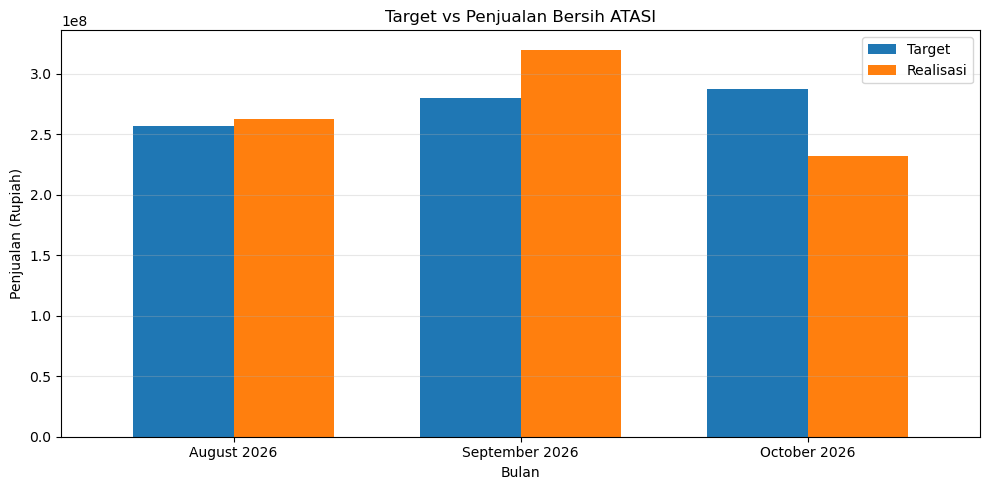

In [27]:
ax = laporan_bulanan[
    ["Target (Rp)", "Penjualan Bersih (Rp)"]
].plot(
    kind="bar",
    figsize=(10, 5),
    width=0.7
)

plt.title("Target vs Penjualan Bersih ATASI")
plt.xlabel("Bulan")
plt.ylabel("Penjualan (Rupiah)")
plt.xticks(rotation=0)
plt.legend(["Target", "Realisasi"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

8. Menyimpan hasil analisis

In [28]:
laporan_bulanan.to_csv(
    "output/capaian_bulanan.csv"
)

print("Analisis bulanan berhasil disimpan.")

Analisis bulanan berhasil disimpan.


# **Analisis detail penjualan Oktober berdasarkan wilayah dan kanal**

1. Menentukan bulan analisis

In [29]:
bulan_analisis = pd.Timestamp("2026-10-01")

print("Bulan analisis:", bulan_analisis.strftime("%B %Y"))

Bulan analisis: October 2026


2. Memfilter transaksi Oktober

In [30]:
print("=== DATA TRANSAKSI OKTOBER ===")

oktober = df[df["Bulan"] == bulan_analisis].copy()

print("Jumlah transaksi Oktober:", len(oktober))

display(oktober.head())

=== DATA TRANSAKSI OKTOBER ===
Jumlah transaksi Oktober: 148


,ID Baris,ID Pesanan,Tanggal Pesanan,Wilayah,Kanal,SKU,Qty Pesan,Harga Bersih per Unit (Rp),Status,Bulan,Penjualan Bersih (Rp)
326,321,INV-0321,2026-10-03,Banyuwangi,B2B,AZE,35,135000,Selesai,2026-10-01,4725000
327,322,INV-0322,2026-10-07,Banyuwangi,B2B,AZE,17,129000,Selesai,2026-10-01,2193000
328,323,INV-0323,2026-10-15,Banyuwangi,B2B,AZE,24,129000,Selesai,2026-10-01,3096000
329,324,INV-0324,2026-10-18,Banyuwangi,B2B,AZE,19,133000,Selesai,2026-10-01,2527000
330,325,INV-0325,2026-10-25,Banyuwangi,B2B,AZE,14,129000,Selesai,2026-10-01,1806000


3. Menghitung realisasi per wilayah dan kanal

In [31]:
print("=== REALISASI PENJUALAN OKTOBER ===")

realisasi_oktober = (
    oktober.groupby(["Wilayah", "Kanal"])
    ["Penjualan Bersih (Rp)"]
    .sum()
    .reset_index()
)

display(realisasi_oktober)

=== REALISASI PENJUALAN OKTOBER ===


,Wilayah,Kanal,Penjualan Bersih (Rp)
0,Banyuwangi,B2B,49390000
1,Banyuwangi,Marketplace,13019000
2,Bondowoso,B2B,66943000
3,Bondowoso,Marketplace,14666000
4,Jember,B2B,75782000
5,Jember,Marketplace,11953000


4. Mengambil target penjualan Oktober

In [32]:
print("=== TARGET PENJUALAN OKTOBER ===")

target_oktober = target[
    target["Bulan"] == bulan_analisis
].copy()

target_oktober = (
    target_oktober.groupby(["Wilayah", "Kanal"])
    ["Target Bersih (Rp)"]
    .sum()
    .reset_index()
)

display(target_oktober)

=== TARGET PENJUALAN OKTOBER ===


,Wilayah,Kanal,Target Bersih (Rp)
0,Banyuwangi,B2B,92000000
1,Banyuwangi,Marketplace,18000000
2,Bondowoso,B2B,62000000
3,Bondowoso,Marketplace,15000000
4,Jember,B2B,80000000
5,Jember,Marketplace,20300000


5. Menggabungkan target dan realisasi

In [33]:
print("=== PENGGABUNGAN TARGET DAN REALISASI ===")

detail_oktober = pd.merge(
    target_oktober,
    realisasi_oktober,
    on=["Wilayah", "Kanal"],
    how="left"
)

detail_oktober["Penjualan Bersih (Rp)"] = (
    detail_oktober["Penjualan Bersih (Rp)"].fillna(0)
)

display(detail_oktober)

=== PENGGABUNGAN TARGET DAN REALISASI ===


,Wilayah,Kanal,Target Bersih (Rp),Penjualan Bersih (Rp)
0,Banyuwangi,B2B,92000000,49390000
1,Banyuwangi,Marketplace,18000000,13019000
2,Bondowoso,B2B,62000000,66943000
3,Bondowoso,Marketplace,15000000,14666000
4,Jember,B2B,80000000,75782000
5,Jember,Marketplace,20300000,11953000


6. Menghitung selisih target dan realisasi

In [34]:
print("=== SELISIH TARGET DAN REALISASI ===")

detail_oktober["Selisih (Rp)"] = (
    detail_oktober["Penjualan Bersih (Rp)"]
    - detail_oktober["Target Bersih (Rp)"]
)

display(detail_oktober[[
    "Wilayah",
    "Kanal",
    "Selisih (Rp)"
]])

=== SELISIH TARGET DAN REALISASI ===


,Wilayah,Kanal,Selisih (Rp)
0,Banyuwangi,B2B,-42610000
1,Banyuwangi,Marketplace,-4981000
2,Bondowoso,B2B,4943000
3,Bondowoso,Marketplace,-334000
4,Jember,B2B,-4218000
5,Jember,Marketplace,-8347000


7. Menghitung persentase capaian

In [35]:
print("=== PERSENTASE CAPAIAN OKTOBER ===")

detail_oktober["Capaian (%)"] = np.where(
    detail_oktober["Target Bersih (Rp)"] > 0,
    detail_oktober["Penjualan Bersih (Rp)"]
    / detail_oktober["Target Bersih (Rp)"] * 100,
    0
)

display(detail_oktober[[
    "Wilayah",
    "Kanal",
    "Capaian (%)"
]])

=== PERSENTASE CAPAIAN OKTOBER ===


,Wilayah,Kanal,Capaian (%)
0,Banyuwangi,B2B,53.684783
1,Banyuwangi,Marketplace,72.327778
2,Bondowoso,B2B,107.972581
3,Bondowoso,Marketplace,97.773333
4,Jember,B2B,94.727500
5,Jember,Marketplace,58.881773


8. Mengurutkan berdasarkan selisih terendah

In [36]:
print("=== URUTAN PRIORITAS PENANGANAN ===")

detail_oktober = detail_oktober.sort_values(
    "Selisih (Rp)"
).reset_index(drop=True)

display(detail_oktober)

=== URUTAN PRIORITAS PENANGANAN ===


,Wilayah,Kanal,Target Bersih (Rp),Penjualan Bersih (Rp),Selisih (Rp),Capaian (%)
0,Banyuwangi,B2B,92000000,49390000,-42610000,53.684783
1,Jember,Marketplace,20300000,11953000,-8347000,58.881773
2,Banyuwangi,Marketplace,18000000,13019000,-4981000,72.327778
3,Jember,B2B,80000000,75782000,-4218000,94.727500
4,Bondowoso,Marketplace,15000000,14666000,-334000,97.773333
5,Bondowoso,B2B,62000000,66943000,4943000,107.972581


9. Menampilkan detail penjualan Oktober

In [37]:
print("=== DETAIL PENJUALAN OKTOBER PER WILAYAH DAN KANAL ===")

display(
    detail_oktober.style.format({
        "Target Bersih (Rp)": "Rp{:,.0f}",
        "Penjualan Bersih (Rp)": "Rp{:,.0f}",
        "Selisih (Rp)": "Rp{:,.0f}",
        "Capaian (%)": "{:.2f}%"
    })
)

=== DETAIL PENJUALAN OKTOBER PER WILAYAH DAN KANAL ===


,Wilayah,Kanal,Target Bersih (Rp),Penjualan Bersih (Rp),Selisih (Rp),Capaian (%)
0,Banyuwangi,B2B,"Rp92,000,000","Rp49,390,000","Rp-42,610,000",53.68%
1,Jember,Marketplace,"Rp20,300,000","Rp11,953,000","Rp-8,347,000",58.88%
2,Banyuwangi,Marketplace,"Rp18,000,000","Rp13,019,000","Rp-4,981,000",72.33%
3,Jember,B2B,"Rp80,000,000","Rp75,782,000","Rp-4,218,000",94.73%
4,Bondowoso,Marketplace,"Rp15,000,000","Rp14,666,000","Rp-334,000",97.77%
5,Bondowoso,B2B,"Rp62,000,000","Rp66,943,000","Rp4,943,000",107.97%


10. Membuat grafik selisih target dan realisasi

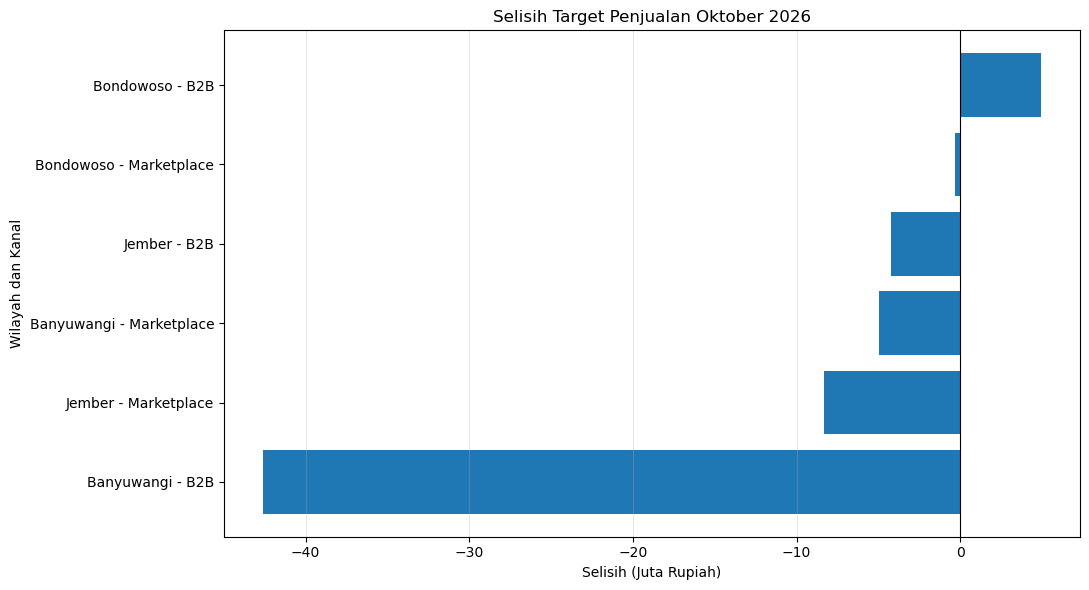

In [38]:
plt.figure(figsize=(11, 6))

label = (
    detail_oktober["Wilayah"]
    + " - "
    + detail_oktober["Kanal"]
)

plt.barh(
    label,
    detail_oktober["Selisih (Rp)"] / 1_000_000
)

plt.axvline(0, color="black", linewidth=0.8)

plt.title("Selisih Target Penjualan Oktober 2026")
plt.xlabel("Selisih (Juta Rupiah)")
plt.ylabel("Wilayah dan Kanal")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

11. Menyimpan hasil analisis

In [39]:
detail_oktober.to_csv(
    "output/detail_penjualan_oktober.csv",
    index=False
)

print("Analisis Oktober berhasil disimpan.")

Analisis Oktober berhasil disimpan.


# **Identifikasi maksimal tiga temuan utama**

Tujuan:
- Mengambil tiga kombinasi wilayah dan kanal dengan kekurangan terbesar.
- Mengidentifikasi dugaan penyebab.
- Menghubungkan temuan dengan data stok kosong.
- Menentukan data tambahan yang perlu diperiksa.

In [40]:
# Mengambil tiga kombinasi dengan selisih terendah
temuan = detail_oktober.nsmallest(
    3, "Selisih (Rp)"
).copy()

# Data stok Oktober
stok_oktober = stok[
    stok["Bulan"] == pd.Timestamp("2026-10-01")
].copy()

# Total hari stok kosong per wilayah
stok_wilayah = (
    stok_oktober.groupby("Wilayah")
    ["Hari Stok Kosong"]
    .sum()
    .reset_index()
)

stok_wilayah.columns = [
    "Wilayah",
    "Total Hari Stok Kosong"
]

# Gabungkan dengan temuan
temuan = temuan.merge(
    stok_wilayah,
    on="Wilayah",
    how="left"
)

# Mengisi nilai kosong jika ada
temuan["Total Hari Stok Kosong"] = (
    temuan["Total Hari Stok Kosong"].fillna(0)
)

# Membuat dugaan awal
def buat_dugaan(row):

    if row["Total Hari Stok Kosong"] > 0:
        return (
            "Potensi keterbatasan ketersediaan stok. "
            "Perlu dicek kesesuaian SKU yang kosong "
            "dengan produk yang diminta pelanggan."
        )

    return (
        "Belum ada indikasi hari stok kosong pada "
        "wilayah tersebut berdasarkan data Oktober. "
        "Perlu memeriksa aktivitas penjualan dan permintaan."
    )

temuan["Dugaan Awal"] = temuan.apply(
    buat_dugaan,
    axis=1
)

# Data tambahan yang perlu diperiksa
temuan["Data untuk Verifikasi"] = (
    "Riwayat stok harian per SKU, pesanan tidak terpenuhi, "
    "jumlah permintaan, transaksi batal, dan aktivitas sales."
)

print("=== TIGA TEMUAN UTAMA ===")

display(
    temuan[[
        "Wilayah",
        "Kanal",
        "Target Bersih (Rp)",
        "Penjualan Bersih (Rp)",
        "Selisih (Rp)",
        "Capaian (%)",
        "Total Hari Stok Kosong",
        "Dugaan Awal",
        "Data untuk Verifikasi"
    ]].style.format({
        "Target Bersih (Rp)": "Rp{:,.0f}",
        "Penjualan Bersih (Rp)": "Rp{:,.0f}",
        "Selisih (Rp)": "Rp{:,.0f}",
        "Capaian (%)": "{:.2f}%"
    })
)

# Simpan hasil
temuan.to_csv(
    "output/temuan_utama.csv",
    index=False
)

print("Temuan utama berhasil disimpan.")

=== TIGA TEMUAN UTAMA ===


,Wilayah,Kanal,Target Bersih (Rp),Penjualan Bersih (Rp),Selisih (Rp),Capaian (%),Total Hari Stok Kosong,Dugaan Awal,Data untuk Verifikasi
0,Banyuwangi,B2B,"Rp92,000,000","Rp49,390,000","Rp-42,610,000",53.68%,15,Potensi keterbatasan ketersediaan stok. Perlu dicek kesesuaian SKU yang kosong dengan produk yang diminta pelanggan.,"Riwayat stok harian per SKU, pesanan tidak terpenuhi, jumlah permintaan, transaksi batal, dan aktivitas sales."
1,Jember,Marketplace,"Rp20,300,000","Rp11,953,000","Rp-8,347,000",58.88%,3,Potensi keterbatasan ketersediaan stok. Perlu dicek kesesuaian SKU yang kosong dengan produk yang diminta pelanggan.,"Riwayat stok harian per SKU, pesanan tidak terpenuhi, jumlah permintaan, transaksi batal, dan aktivitas sales."
2,Banyuwangi,Marketplace,"Rp18,000,000","Rp13,019,000","Rp-4,981,000",72.33%,15,Potensi keterbatasan ketersediaan stok. Perlu dicek kesesuaian SKU yang kosong dengan produk yang diminta pelanggan.,"Riwayat stok harian per SKU, pesanan tidak terpenuhi, jumlah permintaan, transaksi batal, dan aktivitas sales."


Temuan utama berhasil disimpan.


# **Usulan dua tindakan untuk dua minggu ke depan**

In [41]:
# Mengambil dua wilayah dan kanal dengan gap terbesar
prioritas = detail_oktober.nsmallest(
    2, "Selisih (Rp)"
).reset_index(drop=True)

# Menyusun dua tindakan
daftar_tindakan = []

for i, row in prioritas.iterrows():

    if i == 0:
        tindakan = (
            "Prioritaskan pemulihan penjualan B2B melalui "
            "kunjungan pelanggan, follow-up pelanggan aktif "
            "dan tidak aktif, serta pemeriksaan ketersediaan "
            "SKU yang paling banyak diminta."
        )

        penanggung_jawab = (
            "Sales Supervisor dan Tim Sales Wilayah"
        )

        deadline = "Hari ke-14"

        ukuran = (
            "Nilai pesanan B2B meningkat dibandingkan "
            "baseline dua minggu sebelumnya dan "
            "jumlah pelanggan yang melakukan pemesanan meningkat."
        )

        risiko = (
            "Pelanggan belum bersedia melakukan pemesanan "
            "atau stok produk belum tersedia."
        )

    else:
        tindakan = (
            "Evaluasi performa Marketplace, periksa "
            "produk yang paling banyak dilihat tetapi "
            "belum dibeli, optimalkan katalog, promosi, "
            "dan respons pelanggan."
        )

        penanggung_jawab = (
            "Marketplace Officer dan Marketing"
        )

        deadline = "Hari ke-14"

        ukuran = (
            "Peningkatan jumlah pesanan, konversi pembelian, "
            "dan penjualan bersih Marketplace dibandingkan "
            "baseline dua minggu sebelumnya."
        )

        risiko = (
            "Promosi tidak meningkatkan konversi atau "
            "terjadi persaingan harga."
        )

    daftar_tindakan.append({
        "Prioritas": i + 1,
        "Wilayah": row["Wilayah"],
        "Kanal": row["Kanal"],
        "Gap Oktober (Rp)": row["Selisih (Rp)"],
        "Tindakan": tindakan,
        "Penanggung Jawab": penanggung_jawab,
        "Batas Waktu": deadline,
        "Ukuran Keberhasilan": ukuran,
        "Risiko/Asumsi": risiko
    })

rencana_tindakan = pd.DataFrame(daftar_tindakan)

print("=== RENCANA TINDAKAN 14 HARI ===")

for _, row in rencana_tindakan.iterrows():

    print("\nPRIORITAS", row["Prioritas"])
    print("Wilayah:", row["Wilayah"])
    print("Kanal:", row["Kanal"])
    print("Gap:", f"Rp{row['Gap Oktober (Rp)']:,.0f}")
    print("Tindakan:", row["Tindakan"])
    print("Penanggung Jawab:", row["Penanggung Jawab"])
    print("Batas Waktu:", row["Batas Waktu"])
    print("Ukuran Keberhasilan:", row["Ukuran Keberhasilan"])
    print("Risiko/Asumsi:", row["Risiko/Asumsi"])

rencana_tindakan.to_csv(
    "output/rencana_tindakan_14_hari.csv",
    index=False
)

print("\nRencana tindakan berhasil disimpan.")

=== RENCANA TINDAKAN 14 HARI ===

PRIORITAS 1
Wilayah: Banyuwangi
Kanal: B2B
Gap: Rp-42,610,000
Tindakan: Prioritaskan pemulihan penjualan B2B melalui kunjungan pelanggan, follow-up pelanggan aktif dan tidak aktif, serta pemeriksaan ketersediaan SKU yang paling banyak diminta.
Penanggung Jawab: Sales Supervisor dan Tim Sales Wilayah
Batas Waktu: Hari ke-14
Ukuran Keberhasilan: Nilai pesanan B2B meningkat dibandingkan baseline dua minggu sebelumnya dan jumlah pelanggan yang melakukan pemesanan meningkat.
Risiko/Asumsi: Pelanggan belum bersedia melakukan pemesanan atau stok produk belum tersedia.

PRIORITAS 2
Wilayah: Jember
Kanal: Marketplace
Gap: Rp-8,347,000
Tindakan: Evaluasi performa Marketplace, periksa produk yang paling banyak dilihat tetapi belum dibeli, optimalkan katalog, promosi, dan respons pelanggan.
Penanggung Jawab: Marketplace Officer dan Marketing
Batas Waktu: Hari ke-14
Ukuran Keberhasilan: Peningkatan jumlah pesanan, konversi pembelian, dan penjualan bersih Marketplac